# 13장 완전한 위계와 다중 감각 (실습)

12장의 위계는 위에서 아래로만 메시지가 흘렀다. 이번에는 아래 캡슐의 원인 상태가 위 캡슐의 감각이 된다. 아래 캡슐의 원인 상태 예측 오차 ε̃v(1) 와 위 캡슐의 감각 예측 오차 ε̃y(2) 는 같은 양이고, 정밀도 가중 오차 ξ 가 위로 올라간다. 아래 캡슐은 수온 하나로 시작하고, 마지막에 수온·압력·빛 세 감각을 함께 쓴다.

1. 완전한 위계: 메시지의 고리
2. 임베딩 차수
3. 유색 잡음과 행동 학습률 — 위계는 학습률을 마음대로 올리지 못하게 한다
4. 공유된 정밀도 Πv(1) = Πy(2)
5. 다중 감각: 수온, 압력, 빛을 함께 쓰는 아래 캡슐

실패 조건은 위계에서 행동 학습률을 지나치게 키우는 경우다.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import koreanize_matplotlib  # 한글 글꼴과 마이너스 기호 설정
from scipy.linalg import cholesky, toeplitz, inv, block_diag

SEED = 42
np.random.seed(SEED)
plt.rcParams.update({"figure.figsize": (6.4, 3.2), "figure.dpi": 200,
                     "axes.spines.top": False, "axes.spines.right": False})

dt, T = 0.005, 20.0
t = np.arange(0, T + dt / 2, dt)
N = t.size

def derivativeD(p): return np.eye(p + 1, k=1)

def temporalC(p, s2):
    q = np.arange(p + 1); r = np.zeros(1 + 2 * p)
    r[2 * q] = np.cumprod(1 - 2 * q) / (2 * s2)**q
    S = np.empty((0, p + 1))
    for i in range(p + 1):
        S = np.vstack([S, r[q + i]]); r = -r
    return S

def makeNoise(C, s2, t):
    C = np.atleast_2d(C)
    w = cholesky(C, lower=True) @ np.random.randn(C.shape[1], np.size(t))
    if s2 <= 1e-5:
        return w
    P = toeplitz(np.exp(-t**2 / (2 * s2)))
    return w @ (P @ np.diag(1 / np.sqrt(np.diag(P.T @ P))))

SENSORS = {
    "temp":  (lambda x: 25 - 16 / (1 + np.exp(5 - x / 5)),
              lambda x: -16 / 5 * np.exp(5 - x / 5) / (1 + np.exp(5 - x / 5))**2),
    "pres":  (lambda x: (101326 + 980 * x) / 101326, lambda x: 980 / 101326 + 0 * x),
    "light": (lambda x: np.exp(-3 * x / 100),          lambda x: -3 / 100 * np.exp(-3 * x / 100)),
}
print("준비 완료")

준비 완료


## 1. 환경과 두 종류의 캡슐

환경은 12장과 같은 Hydar 의 상태 공간(x′ = u)과 세 감각이다(먹이는 쓰지 않는다). 유색 잡음은 깊이와 각 감각에 따로 섞는다. 감각마다 잡음의 크기를 다르게 줄 수 있다.

캡슐은 두 종류다.
- 아래 캡슐(감각 있음): 감각 목록을 받아 감각마다 예측 오차를 만들고, 행동을 낸다. 위로는 ξ̃v(1) = Π̃v(1) ε̃v(1) 를 올려 보낸다.
- 위 캡슐(감각 없음): 감각 대신 아래에서 올라온 ξ̃v(1) 를 자기 감각의 정밀도 가중 오차 ξ̃y(2) 로 받는다. 감각 사상은 g(2)(μ) = μ 이고, 그 예측이 아래 캡슐의 사전이 된다.

In [2]:
class HydarEnv:
    def __init__(self, t, p=1, noise="none", s2_x=0.1, s2_y=None, seed=42):
        s2_y = s2_y or {"temp": 0.1, "pres": 1e-6, "light": 1e-4}
        self.t, self.dt, self.p = t, t[1] - t[0], p
        np.random.seed(seed)
        if noise == "smooth":
            n = makeNoise(np.eye(4), 1 / 2000, t)
            self.w = n[0] * np.sqrt(s2_x)
            self.z = {k: n[i + 1] * np.sqrt(s2_y[k]) for i, k in enumerate(SENSORS)}
        else:
            self.w = np.zeros(t.size); self.z = {k: np.zeros(t.size) for k in SENSORS}

    def _obs(self, xd):
        out = {}
        for k, (g, dg) in SENSORS.items():
            y = np.zeros((self.p + 1, 1)); y[0] = g(self.x) + self.z[k][self.i]
            if self.p >= 1:
                y[1] = dg(self.x) * xd
            out[k] = y
        return out

    def reset(self, x_init):
        self.i, self.x = 0, x_init
        return self._obs(0.0)

    def step(self, u):
        self.i += 1
        xd = u + self.w[self.i]
        self.x += self.dt * xd
        return self._obs(xd)


class Capsule:
    """일반화 좌표의 캡슐. sensors 가 있으면 감각을 받는 아래 캡슐, 없으면 ξ 를 받는 위 캡슐."""

    def __init__(self, x0, p, s2_x, s2_v, a_x, a_v, a_u=0.0, sensors=None, s2_y=None, s2=1 / 64, fwd="sign"):
        self.p, self.a_x, self.a_v, self.a_u, self.fwd = p, a_x, a_v, a_u, fwd
        self.I, self.D = np.eye(p + 1), derivativeD(p)
        self.e0 = self.I[:, :1]
        self.mu_x, self.mu_v, self.u = self.e0 * x0, self.e0 * x0, 0.0
        S = temporalC(p, s2)
        self.Pi_x, self.Pi_v = inv(np.kron(S, s2_x)), inv(np.kron(S, s2_v))
        self.sensors = sensors or []
        self.Pi_y = {k: inv(np.kron(S, s2_y[k])) for k in self.sensors}

    def g_tilde(self, name):
        if name is None:                                         # 위 캡슐: g(μ) = μ
            return self.mu_x.copy(), 1.0
        g, dg = SENSORS[name]
        g1 = dg(self.mu_x[0, 0])
        return self.e0 * g(self.mu_x[0, 0]) + (1 - self.e0) * g1 * self.mu_x, g1

    def step(self, eta, ys=None, xi_up=None, act=False):
        mx, mv = self.mu_x, self.mu_v
        eps_x = self.D @ mx - (-mx + mv)
        xi_x = self.Pi_x @ eps_x
        xi_v = self.Pi_v @ (mv - eta)                            # 위로 올라갈 정밀도 가중 오차
        dF_x = (self.D + self.I).T @ xi_x
        du = 0.0
        if xi_up is not None:                                    # 위 캡슐: 아래에서 올라온 오차가 감각 오차
            dF_x = dF_x - xi_up
        for k in self.sensors:
            gt, g1 = self.g_tilde(k)
            xi_y = self.Pi_y[k] @ (ys[k] - gt)
            dF_x = dF_x - g1 * xi_y
            w = np.sign(g1) if self.fwd == "sign" else g1          # 부호 전방 모델 또는 기울기 g′ 로 가중
            du += w * np.ones(self.p + 1) @ xi_y[:, 0]
        dF_v = -xi_x + xi_v
        self.mu_x = mx + dt * (self.D @ mx - self.a_x * dF_x)
        self.mu_v = mv + dt * (self.D @ mv - self.a_v * dF_v)
        if act:
            self.u += dt * -self.a_u * du
        return xi_v


def run(p=1, prior=15.0, x_init=25.0, s2_v1=0.1, a_v1=1.0, a_u=5.0, noise="none", sensors=("temp",),
        s2_y_model=None, s2_y_env=None, t_act=3.0, top=True, fwd="sign"):
    s2_y_model = s2_y_model or {"temp": 0.1, "pres": 1e-6, "light": 1e-4}
    s2 = 1 / 2000 if noise == "smooth" else 1 / 64
    env = HydarEnv(t, p, noise=noise, s2_y=s2_y_env)
    ys = env.reset(x_init)
    bot = Capsule(prior, p, 0.1, s2_v1, 3.0, a_v1, a_u, list(sensors), s2_y_model, s2, fwd)
    tc = Capsule(prior, p, 0.1, 0.1, 3.0, 1.0, s2=s2)
    rec = {k: np.zeros(N) for k in ["x", "mx1", "mv1", "eta1", "mx2", "mv2", "u"]}
    rec["x"][0] = x_init
    xi_v1 = np.zeros((p + 1, 1))
    for i in range(1, N):
        ys = env.step(bot.u)
        if top:
            tc.step(tc.e0 * prior, xi_up=xi_v1)
            eta1 = tc.mu_x.copy()                                # 위 캡슐의 감각 예측 = 아래 캡슐의 사전
        else:
            eta1 = bot.e0 * prior
        xi_v1 = bot.step(eta1, ys, act=t[i] > t_act)
        for k, v in [("x", env.x), ("mx1", bot.mu_x[0, 0]), ("mv1", bot.mu_v[0, 0]), ("eta1", eta1[0, 0]),
                     ("mx2", tc.mu_x[0, 0]), ("mv2", tc.mu_v[0, 0]), ("u", bot.u)]:
            rec[k][i] = v
    return rec

def arrival(r, target=15.0, tol=0.5, after=3.0):
    bad = np.where((np.abs(r["x"] - target) >= tol) & (t >= after))[0]
    return t[bad[-1] + 1] if bad.size and bad[-1] + 1 < N else (np.inf if bad.size else after)

print("HydarEnv, Capsule, run 준비 완료")

HydarEnv, Capsule, run 준비 완료


## 2. 완전한 위계 — 메시지의 고리

Hydar 는 깊이 25 에서 출발하고, 위 캡슐의 사전은 15 다. 원본 실험 8.01 의 설정: 아래 캡슐 분산 0.1, αx = 3, αv = 1, αu = 5, 위 캡슐 분산 0.1, αx = 3, αv = 1, p = 1, 잡음 없음, 행동은 3 초부터. 행동 직전과 끝에서 고리의 네 고리를 비교한다.

In [3]:
r = run()
for sec in [2.99, 5.0, 8.0, 20.0]:
    k = min(int(round(sec / dt)), N - 1)
    print(f"t={sec:5.2f}s  깊이 {r['x'][k]:6.2f}  | 아래: μx {r['mx1'][k]:6.2f}  μv {r['mv1'][k]:6.2f}  사전 η {r['eta1'][k]:6.2f}"
          f"  | 위: μx {r['mx2'][k]:6.2f}  μv {r['mv2'][k]:6.2f}")
print(f"15 ± 0.5 cm 도착: {arrival(r):.2f}s")
r0 = run(top=False)
print(f"(비교) 위 캡슐 없이 고정 사전 15: 도착 {arrival(r0):.2f}s,  20초 깊이 {r0['x'][-1]:.2f}")

t= 2.99s  깊이  25.00  | 아래: μx  24.14  μv  16.24  사전 η  16.27  | 위: μx  16.27  μv  14.88
t= 5.00s  깊이  15.82  | 아래: μx  15.92  μv  13.15  사전 η  13.40  | 위: μx  13.40  μv  14.80
t= 8.00s  깊이  13.85  | 아래: μx  13.87  μv  13.67  사전 η  13.75  | 위: μx  13.75  μv  15.00
t=20.00s  깊이  15.02  | 아래: μx  15.02  μv  15.01  사전 η  15.01  | 위: μx  15.01  μv  15.00
15 ± 0.5 cm 도착: 10.84s
(비교) 위 캡슐 없이 고정 사전 15: 도착 7.49s,  20초 깊이 15.00


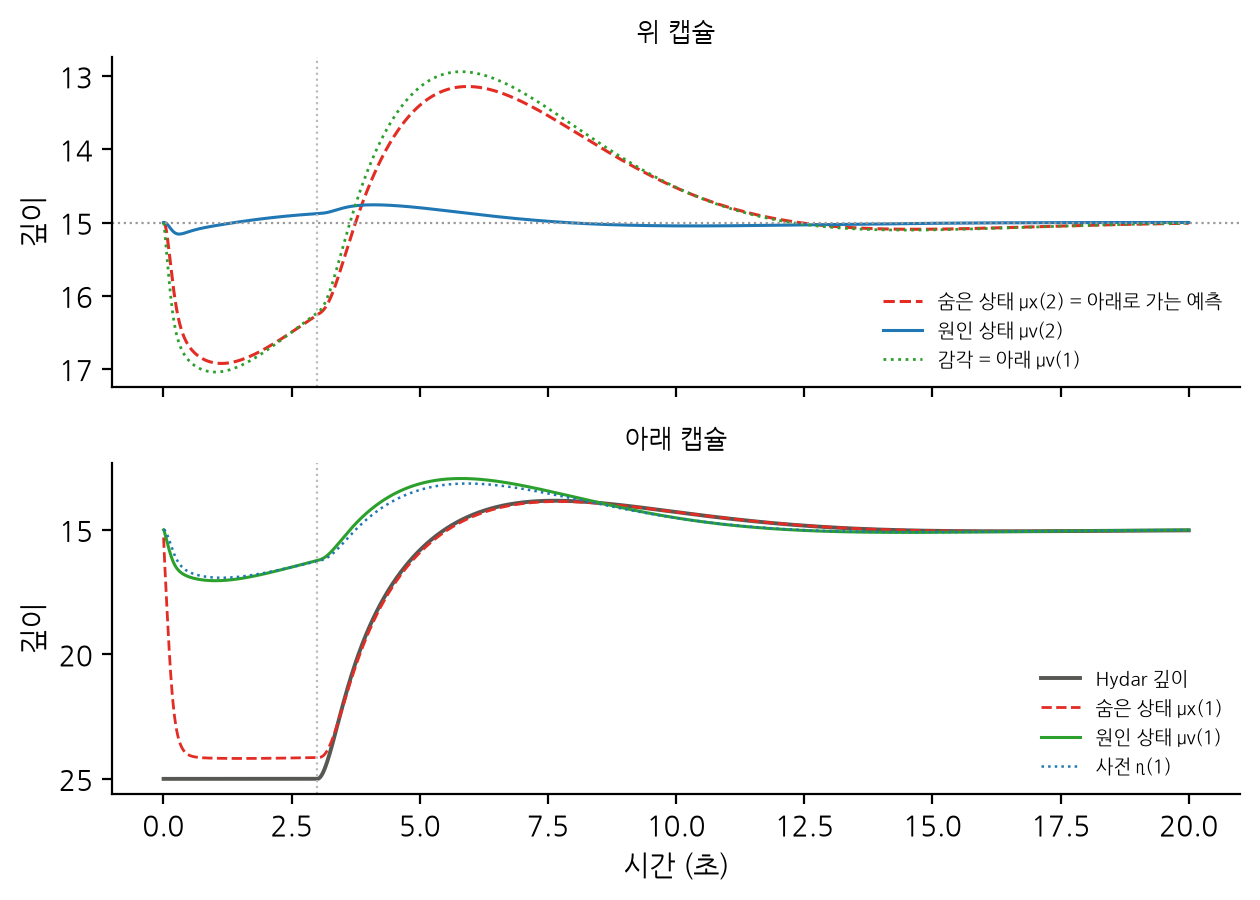

In [4]:
fig, ax = plt.subplots(2, 1, sharex=True, figsize=(6.4, 4.6))
ax[0].plot(t[1:], r["mx2"][1:], color="#E32C24", lw=1.1, ls="--", label="숨은 상태 μx(2) = 아래로 가는 예측")
ax[0].plot(t[1:], r["mv2"][1:], color="#1f77b4", lw=1.1, label="원인 상태 μv(2)")
ax[0].plot(t[1:], r["mv1"][1:], color="#2ca02c", lw=1.0, ls=":", label="감각 = 아래 μv(1)")
ax[0].axhline(15, color="#999999", lw=0.8, ls=":")
ax[0].set_title("위 캡슐", fontsize=9); ax[0].set_ylabel("깊이")
ax[0].legend(frameon=False, fontsize=7, loc="lower right")
ax[1].plot(t[1:], r["x"][1:], color="#575753", lw=1.4, label="Hydar 깊이")
ax[1].plot(t[1:], r["mx1"][1:], color="#E32C24", lw=1.0, ls="--", label="숨은 상태 μx(1)")
ax[1].plot(t[1:], r["mv1"][1:], color="#2ca02c", lw=1.1, label="원인 상태 μv(1)")
ax[1].plot(t[1:], r["eta1"][1:], color="#1f77b4", lw=0.9, ls=":", label="사전 η(1)")
ax[1].set_title("아래 캡슐", fontsize=9); ax[1].set_ylabel("깊이"); ax[1].set_xlabel("시간 (초)")
ax[1].legend(frameon=False, fontsize=7, loc="lower right")
for a_ in ax:
    a_.axvline(3.0, color="#BBBBBB", lw=0.8, ls=":"); a_.invert_yaxis()
fig.tight_layout(); plt.show()

## 3. 임베딩 차수

p = 1, 2, 3 을 비교한다. 원본은 p = 2 에서만 위 캡슐이 오래 걸렸고, 아래 캡슐의 원인 상태 학습률을 1 에서 3 으로 올려 풀었다.

In [5]:
print(" p   αv(1)   도착      20초 깊이   20초 위 μv")
for p, av in [(1, 1.0), (2, 1.0), (2, 3.0), (3, 1.0)]:
    rr = run(p=p, a_v1=av)
    print(f" {p}    {av:.0f}     {arrival(rr):6.2f}s    {rr['x'][-1]:6.2f}      {rr['mv2'][-1]:6.2f}")

 p   αv(1)   도착      20초 깊이   20초 위 μv


 1    1      10.84s     15.02       15.00
 2    1       6.00s     15.14       15.02


 2    3       6.20s     14.93       15.01


 3    1       6.44s     14.94       14.99


## 4. 유색 잡음과 행동 학습률

유색 잡음(매끄러움 1/2000)을 넣고 아래 캡슐 αv = 3 으로 둔다. 행동 학습률 1.5, 5, 50 을 비교하고, 같은 설정의 단일 캡슐(고정 사전 15)과도 비교한다. 목표 깊이 15 를 가로지른 횟수로 진동을 센다.

In [6]:
def crossings(r, target=15.0, after=3.5):
    s = np.sign(r["x"][t > after] - target)
    return int(np.sum(s[1:] != s[:-1]))

print("구조        αu     도착(±1)    15 가로지름   마지막 5초 깊이")
for top, a_u in [(True, 1.5), (True, 5.0), (True, 50.0), (False, 5.0), (False, 50.0)]:
    rr = run(a_v1=3.0, a_u=a_u, noise="smooth", top=top)
    tail = t > 15
    print(f"{'위계' if top else '단일 캡슐':8s}  {a_u:5.1f}   {arrival(rr, tol=1.0):6.2f}s       {crossings(rr):3d}        "
          f"{rr['x'][tail].mean():6.2f}±{rr['x'][tail].std():.2f}")

구조        αu     도착(±1)    15 가로지름   마지막 5초 깊이


위계          1.5    15.04s         2         14.46±0.26


위계          5.0    18.46s        11         14.53±0.65


위계         50.0    19.96s        48         14.42±1.34


단일 캡슐       5.0    19.05s        16         15.07±0.59


단일 캡슐      50.0    19.96s        54         14.98±1.31


## 5. 공유된 정밀도

아래 캡슐의 원인 상태 정밀도 Π̃v(1) 은 위 캡슐 쪽에서 보면 감각 정밀도다. 같은 오차를 공유하기 때문이다. σv(1)² 를 0.1, 1, 10 으로 바꾼다.

In [7]:
print("σv(1)²   행동 직전 아래 μv−η   아래 μv 최솟값   20초 위 μv    도착      20초 깊이")
for s2v in [0.1, 1.0, 10.0]:
    rr = run(s2_v1=s2v)
    k = int(2.99 / dt)
    print(f"{s2v:5.1f}       {rr['mv1'][k] - rr['eta1'][k]:+7.3f}          {rr['mv1'][1:].min():8.2f}       {rr['mv2'][-1]:6.2f}     {arrival(rr):6.2f}s   {rr['x'][-1]:6.2f}")

σv(1)²   행동 직전 아래 μv−η   아래 μv 최솟값   20초 위 μv    도착      20초 깊이
  0.1        -0.028             12.94        15.00      10.84s    15.02
  1.0        +0.164              6.46        15.09        infs    13.70


 10.0        +2.072            -13.61        15.16        infs   -18.11


## 6. 다중 감각

아래 캡슐이 수온, 압력, 빛을 함께 쓴다. 각 감각의 예측 오차가 각자의 정밀도로 더해지고, 행동은 감각마다 부호 전방 모델(압력은 +, 수온과 빛은 −)을 쓴다. 생성 과정에는 유색 잡음을 넣는다. 수온 센서가 망가진 경우(수온 잡음 분산 100 배)도 본다. 생성 모델이 가정하는 감각 분산은 실제 잡음 분산과 같게 둔다.

In [8]:
base = {"temp": 0.1, "pres": 5e-5, "light": 1.5e-4}
broken = {"temp": 10.0, "pres": 5e-5, "light": 1.5e-4}
for k, s2y in base.items():
    g1 = SENSORS[k][1](20.0)
    print(f"{k:5s}  깊이 20 의 기울기 {g1:+.4f}   분산 {s2y:.1e}   정보량 g′²/σ² = {g1**2 / s2y:5.2f}")
print()
print("감각       수온 상태   행동 직전 |μx−x|   도착(±1)   마지막 5초 깊이")
res_ms = {}
for name, sens in [("수온만", ("temp",)), ("세 감각", ("temp", "pres", "light"))]:
    for state, s2y in [("정상", base), ("망가짐", broken)]:
        rr = run(a_v1=3.0, a_u=8.0, noise="smooth", sensors=sens, s2_y_model=s2y, s2_y_env=s2y, fwd="grad")
        res_ms[(name, state)] = rr
        k = int(2.99 / dt); tail = t > 15
        print(f"{name:6s}     {state:4s}        {abs(rr['mx1'][k] - rr['x'][k]):7.3f}        "
              f"{arrival(rr, tol=1.0):6.2f}s     {rr['x'][tail].mean():6.2f}±{rr['x'][tail].std():.2f}")

temp   깊이 20 의 기울기 -0.6292   분산 1.0e-01   정보량 g′²/σ² =  3.96
pres   깊이 20 의 기울기 +0.0097   분산 5.0e-05   정보량 g′²/σ² =  1.87
light  깊이 20 의 기울기 -0.0165   분산 1.5e-04   정보량 g′²/σ² =  1.81

감각       수온 상태   행동 직전 |μx−x|   도착(±1)   마지막 5초 깊이


수온만        정상            0.656         18.68s      14.53±0.39


수온만        망가짐           9.322           infs     -12.85±1.01


세 감각       정상            0.559         12.63s      14.47±0.25


세 감각       망가짐           0.896         12.51s      14.49±0.27


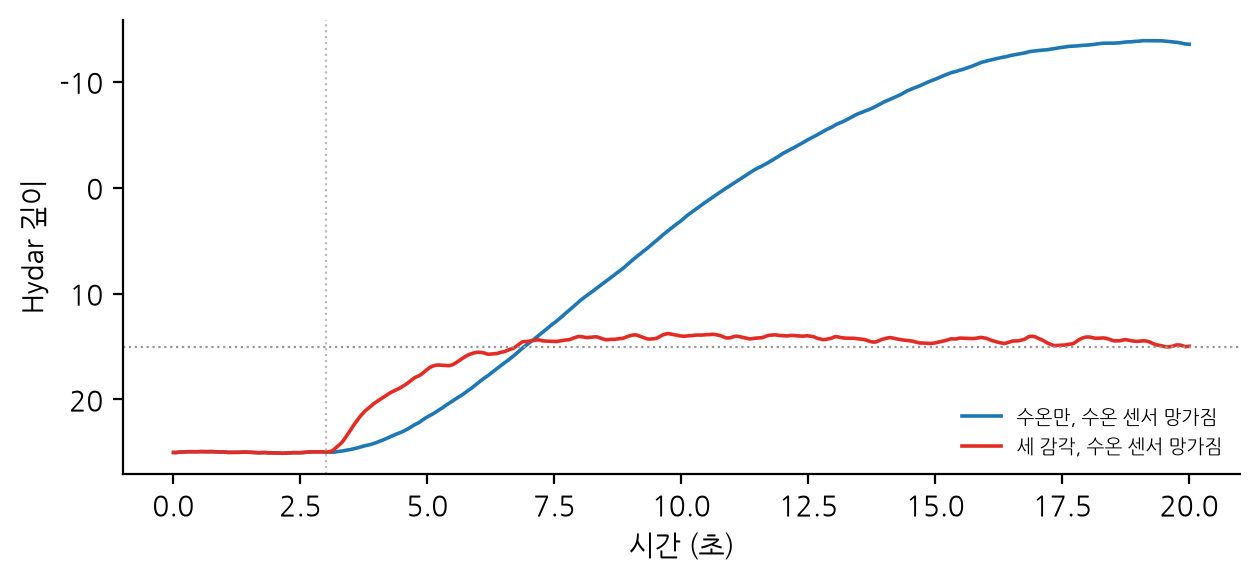

In [9]:
fig, ax = plt.subplots(1, 1, figsize=(6.4, 3.0))
for (name, state), c, ls in [(("수온만", "망가짐"), "#1f77b4", "-"), (("세 감각", "망가짐"), "#E32C24", "-")]:
    rr = res_ms[(name, state)]
    ax.plot(t[1:], rr["x"][1:], color=c, lw=1.3, ls=ls, label=f"{name}, 수온 센서 {state}")
ax.axhline(15, color="#999999", lw=0.8, ls=":")
ax.axvline(3.0, color="#BBBBBB", lw=0.8, ls=":")
ax.invert_yaxis(); ax.set_xlabel("시간 (초)"); ax.set_ylabel("Hydar 깊이")
ax.legend(frameon=False, fontsize=7, loc="lower right")
fig.tight_layout(); plt.show()

## 결론

- 완전한 위계에서 아래 캡슐의 원인 상태가 위 캡슐의 감각이 되고, 위 캡슐의 예측이 아래 캡슐의 사전이 된다. 두 캡슐의 오차가 하나의 고리를 이룬다.
- 유색 잡음 속 위계에서는 행동 학습률을 크게 하면 진동한다. 위계의 위아래 상호작용이 학습률을 단순히 올리는 길을 막는다.
- 아래 캡슐의 원인 상태 정밀도는 위 캡슐의 감각 정밀도와 같은 양이다.
- 여러 감각을 정밀도로 가중해 더하면 한 감각이 망가져도 나머지가 깊이 추정과 행동을 지탱한다.